# 01 - Analisi esplorativa del dataset

Dataset: Rock-Paper-Scissors di Kaggle (drgfreeman). Prima di fare qualsiasi modello controllo:
- struttura delle cartelle e numero di immagini per classe
- dimensioni e canali colore
- file corrotti
- duplicati e quasi-duplicati
- qualche esempio per classe

In [1]:
import os
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import imagehash

DATA_DIR = '../data.nosync/rockpaperscissors'
FIG_DIR = '../results/figures'
OUT_DIR = '../results/metrics'
CLASSES = ['paper', 'rock', 'scissors']
SEED = 42

## Struttura delle cartelle
Conto quanti png ci sono in ogni cartella dell'archivio.

In [2]:
for root, dirs, files in sorted(os.walk(DATA_DIR)):
    n_png = len([f for f in files if f.endswith('.png')])
    if n_png > 0:
        print(root.replace(DATA_DIR + '/', ''), n_png)

paper 712
rock 726
rps-cv-images/paper 712
rps-cv-images/rock 726
rps-cv-images/scissors 750
scissors 750


I file sono 4376, il doppio di quelli dichiarati (2188). La cartella `rps-cv-images` sembra una copia
delle tre cartelle delle classi. Controllo con l'hash MD5 se i file sono proprio gli stessi.

In [3]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

for c in CLASSES:
    a = {md5(os.path.join(DATA_DIR, c, f)) for f in os.listdir(os.path.join(DATA_DIR, c))}
    b = {md5(os.path.join(DATA_DIR, 'rps-cv-images', c, f)) for f in os.listdir(os.path.join(DATA_DIR, 'rps-cv-images', c))}
    print(c, 'copia identica:', a == b)

paper copia identica: True


rock copia identica: True


scissors copia identica: True


È una copia identica. Se leggessi tutte le cartelle in modo ricorsivo ogni foto comparirebbe due volte
(e potrebbe finire sia nel train che nel test). Da qui in poi uso solo le tre cartelle principali.

## Lettura delle immagini
Per ogni immagine salvo dimensioni, modalità colore, hash MD5, perceptual hash (serve dopo per i
quasi-duplicati) e la luminosità media. Se un file non si apre lo segno come corrotto.

In [4]:
rows = []
for c in CLASSES:
    for f in sorted(os.listdir(os.path.join(DATA_DIR, c))):
        path = os.path.join(DATA_DIR, c, f)
        row = {'filename': f, 'label': c, 'path': path, 'md5': md5(path), 'corrupted': False}
        try:
            img = Image.open(path)
            img.load()
            row['width'], row['height'] = img.size
            row['mode'] = img.mode
            row['phash'] = str(imagehash.phash(img))
            arr = np.array(img.convert('RGB')).astype(float)
            row['brightness'] = arr.mean()
            row['mean_r'] = arr[:, :, 0].mean()
            row['mean_g'] = arr[:, :, 1].mean()
            row['mean_b'] = arr[:, :, 2].mean()
        except Exception as e:
            row['corrupted'] = True
            print('errore su', path, e)
        rows.append(row)

df = pd.DataFrame(rows)
print('immagini:', len(df))
print('file corrotti:', df['corrupted'].sum())
df.groupby(['width', 'height', 'mode']).size()

immagini: 2188
file corrotti: 0


width  height  mode
300    200     RGB     2188
dtype: int64

Nessun file corrotto e tutte le immagini sono 300x200 RGB (nessun canale alpha), quindi non devo
scartare niente.

## Numero di immagini per classe
Confronto anche con i numeri scritti nel README del dataset.

          immagini  percentuale  README
paper          712         32.5     710
rock           726         33.2     726
scissors       750         34.3     752


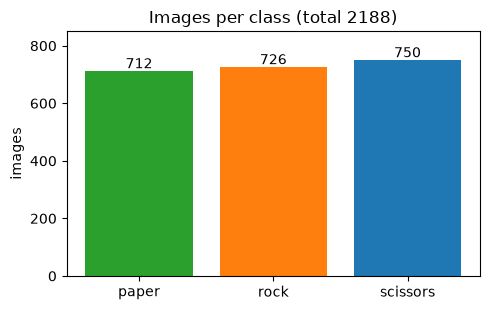

In [5]:
counts = df['label'].value_counts()[CLASSES]
readme = pd.Series({'paper': 710, 'rock': 726, 'scissors': 752})
print(pd.DataFrame({'immagini': counts, 'percentuale': (counts / len(df) * 100).round(1), 'README': readme}))

plt.figure(figsize=(5, 3.2))
plt.bar(CLASSES, counts, color=['tab:green', 'tab:orange', 'tab:blue'])
for i, v in enumerate(counts):
    plt.text(i, v + 10, str(v), ha='center')
plt.ylim(0, 850)
plt.ylabel('images')
plt.title('Images per class (total %d)' % len(df))
plt.tight_layout()
plt.savefig(FIG_DIR + '/eda_class_counts.png', dpi=150)
plt.show()

Le classi sono quasi bilanciate (32-34%), quindi l'accuracy ha senso ma riporterò anche la macro F1.
Rispetto al README ci sono 2 immagini in più in paper e 2 in meno in scissors: forse due foto sono
state spostate di cartella. Non posso saperlo dai file, quindi tengo le etichette delle cartelle e
ci ripenso quando guarderò gli errori dei modelli.

## Esempi per classe

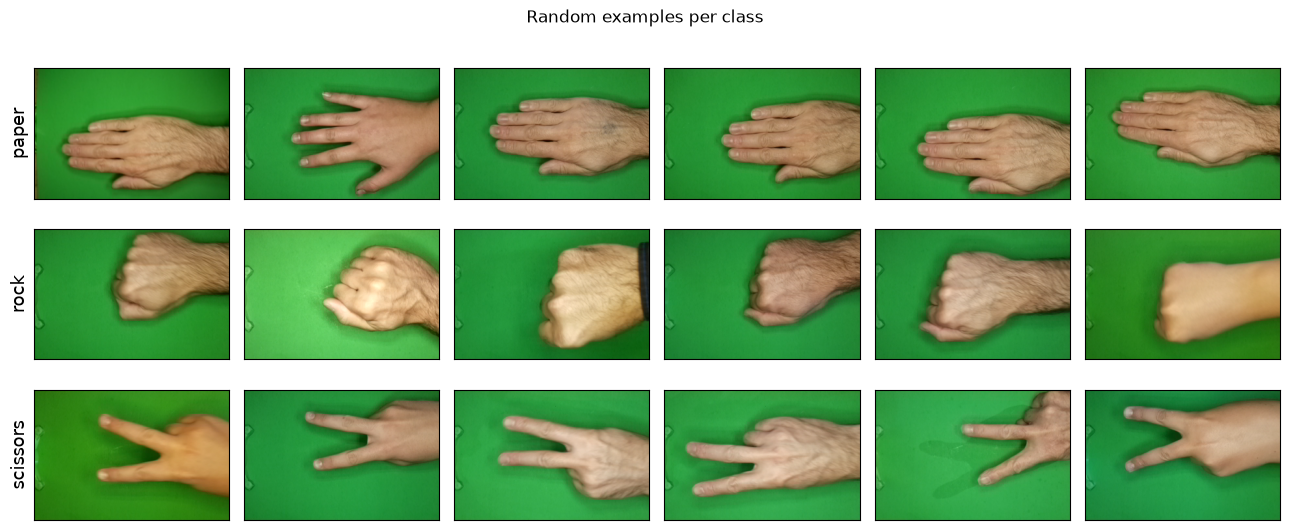

In [6]:
plt.figure(figsize=(13, 5.6))
for r, c in enumerate(CLASSES):
    sample = df[df['label'] == c].sample(6, random_state=SEED)
    for i, path in enumerate(sample['path']):
        plt.subplot(3, 6, r * 6 + i + 1)
        plt.imshow(Image.open(path))
        plt.xticks([])
        plt.yticks([])
        if i == 0:
            plt.ylabel(c, fontsize=13)
plt.suptitle('Random examples per class')
plt.tight_layout()
plt.savefig(FIG_DIR + '/eda_examples.png', dpi=150)
plt.show()

Tutte le foto sono fatte nello stesso modo: sfondo verde, mano che entra da destra, stessa distanza e
luce simile. Per questo il problema è facile su questi dati, ma il modello potrebbe non funzionare su
foto fatte in un altro ambiente.

## Colore e luminosità
Se una classe fosse più chiara o di un colore diverso, il modello potrebbe usare quello invece della
forma della mano.

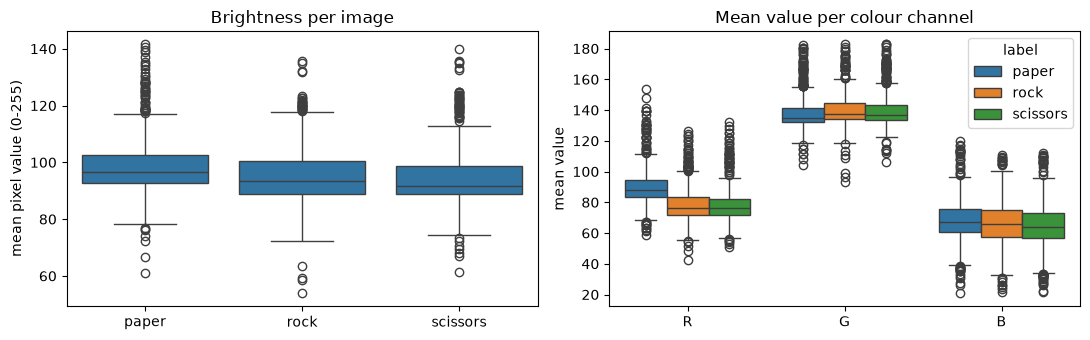

,brightness,mean_r,mean_g,mean_b
label,,,,
paper,99.1,90.4,138.6,68.2
rock,95.3,78.7,141.0,66.3
scissors,94.4,78.2,140.5,64.6


In [7]:
plt.figure(figsize=(11, 3.5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='label', y='brightness', order=CLASSES)
plt.xlabel('')
plt.ylabel('mean pixel value (0-255)')
plt.title('Brightness per image')

plt.subplot(1, 2, 2)
colori = df.melt(id_vars='label', value_vars=['mean_r', 'mean_g', 'mean_b'], var_name='channel')
colori['channel'] = colori['channel'].map({'mean_r': 'R', 'mean_g': 'G', 'mean_b': 'B'})
sns.boxplot(data=colori, x='channel', y='value', hue='label', hue_order=CLASSES)
plt.xlabel('')
plt.ylabel('mean value')
plt.title('Mean value per colour channel')

plt.tight_layout()
plt.savefig(FIG_DIR + '/eda_brightness.png', dpi=150)
plt.show()

df.groupby('label')[['brightness', 'mean_r', 'mean_g', 'mean_b']].mean().round(1)

Provo anche a fare l'immagine media di ogni classe (riduco le foto a 150x100 per fare prima).

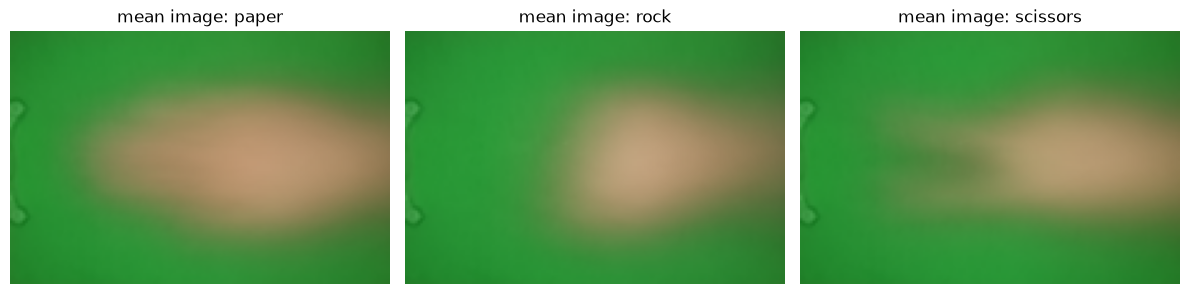

In [8]:
plt.figure(figsize=(12, 2.9))
for i, c in enumerate(CLASSES):
    imgs = [np.array(Image.open(p).convert('RGB').resize((150, 100))) for p in df[df['label'] == c]['path']]
    media = np.mean(imgs, axis=0).astype(np.uint8)
    plt.subplot(1, 3, i + 1)
    plt.imshow(media)
    plt.title('mean image: ' + c)
    plt.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR + '/eda_mean_images.png', dpi=150)
plt.show()

Le differenze di colore sono piccole e dipendono dalla mano (paper è un po' più chiara e rossa perché
la mano aperta copre più foto). Lo sfondo è uguale per tutte le classi.

L'immagine media invece è interessante: la mano è sempre nella stessa posizione e le classi si
distinguono soprattutto per quanto la mano si allunga verso sinistra. Già la media dei pixel separa le
classi, e questo spiega perché anche un modello semplice sui pixel funziona bene. La forma scura sul
bordo sinistro è il supporto della fotocamera, uguale in tutte le foto.

## Duplicati
Prima i duplicati esatti (stesso MD5):

In [9]:
print('file con MD5 uguale a un altro file:', df['md5'].duplicated(keep=False).sum())

file con MD5 uguale a un altro file: 0


Nessun duplicato esatto. Però le foto vengono da un gioco in cui la fotocamera scattava a ogni partita,
quindi ci possono essere foto scattate una dopo l'altra quasi identiche. Se una è nel train e l'altra nel
test, il test diventa troppo facile.

Per trovarle uso il perceptual hash (pHash): ogni immagine diventa un'impronta di 64 bit che dipende dalla
forma generale dell'immagine. Due immagini simili hanno impronte simili, e la distanza è il numero di bit
diversi (distanza di Hamming).

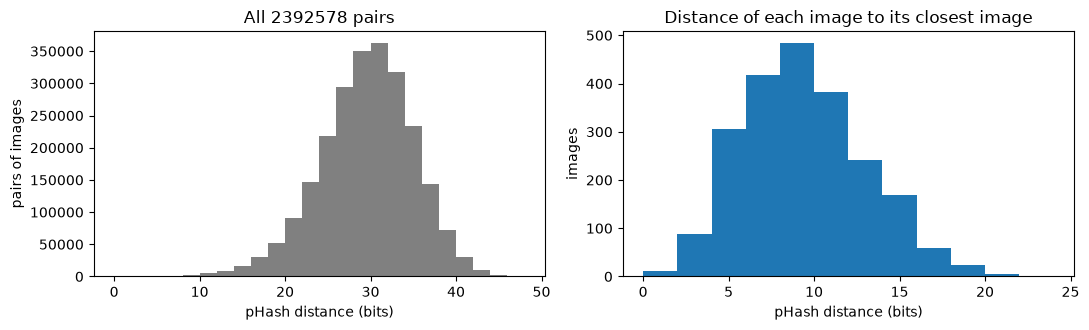

coppie a distanza 0: 6
immagini con un'altra immagine entro 4 bit: 406


In [10]:
# matrice 2188 x 64 con i bit di ogni hash
bits = np.array([imagehash.hex_to_hash(h).hash.flatten() for h in df['phash']]).astype(int)

# distanza di Hamming tra tutte le coppie: conto i bit diversi
dist = bits @ (1 - bits).T + (1 - bits) @ bits.T

n = len(df)
coppie = dist[np.triu_indices(n, k=1)]           # ogni coppia una volta sola
dist_vicina = (dist + np.eye(n, dtype=int) * 64).min(axis=1)   # immagine più vicina (escludo se stessa)

plt.figure(figsize=(11, 3.4))
plt.subplot(1, 2, 1)
plt.hist(coppie, bins=np.arange(0, 50, 2), color='grey')
plt.xlabel('pHash distance (bits)')
plt.ylabel('pairs of images')
plt.title('All %d pairs' % len(coppie))
plt.subplot(1, 2, 2)
plt.hist(dist_vicina, bins=np.arange(0, 26, 2))
plt.xlabel('pHash distance (bits)')
plt.ylabel('images')
plt.title('Distance of each image to its closest image')
plt.tight_layout()
plt.savefig(FIG_DIR + '/eda_phash_distances.png', dpi=150)
plt.show()

print('coppie a distanza 0:', (coppie == 0).sum())
print('immagini con un\'altra immagine entro 4 bit:', (dist_vicina <= 4).sum())

In media due immagini distano circa 28 bit, ma molte hanno una "gemella" a pochi bit. Guardo qualche
coppia a distanza crescente, con accanto la differenza tra i pixel.

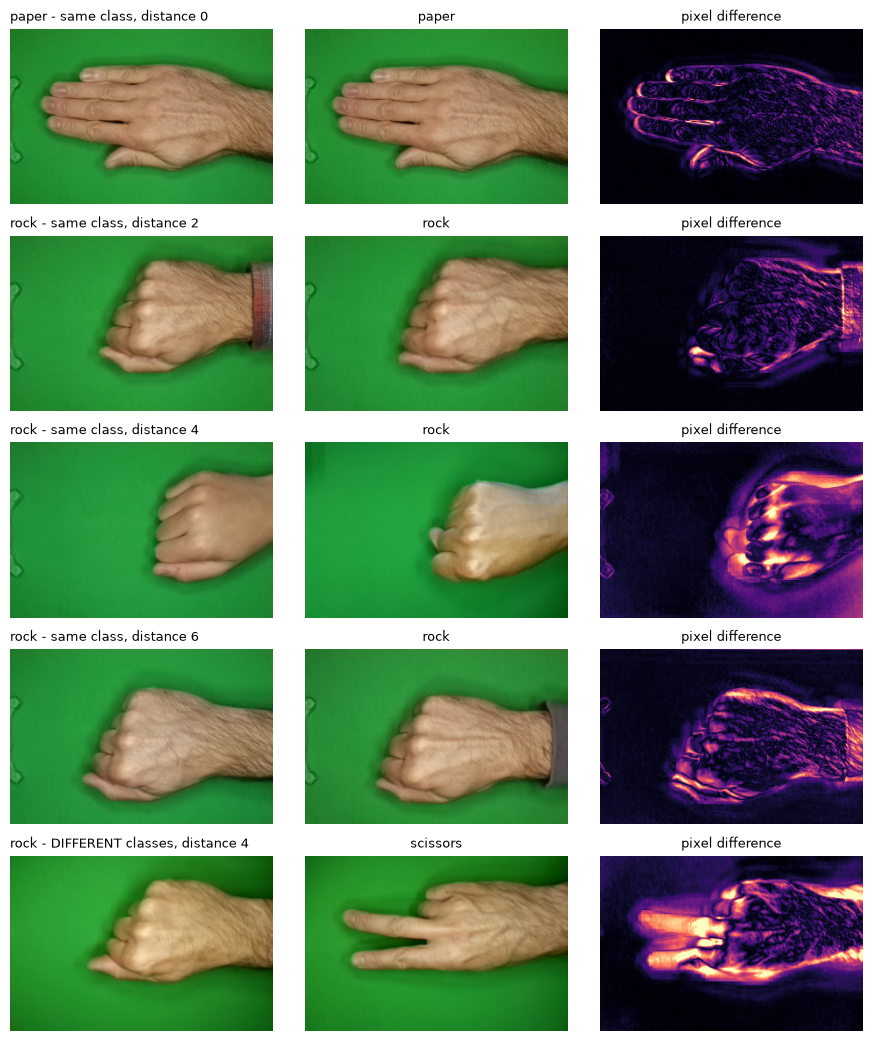

In [11]:
labels = np.array(df['label'].tolist())
stessa_classe = labels[:, None] == labels[None, :]
sopra_diag = np.triu(np.ones((n, n), dtype=bool), k=1)
rng = np.random.default_rng(SEED)

esempi = []
for d in [0, 2, 4, 6]:
    ii, jj = np.where(sopra_diag & stessa_classe & (dist == d))
    k = rng.integers(len(ii))
    esempi.append(('same class, distance %d' % d, ii[k], jj[k]))
# una coppia di classi diverse ma vicina
ii, jj = np.where(sopra_diag & ~stessa_classe & (dist <= 4))
esempi.append(('DIFFERENT classes, distance %d' % dist[ii[0], jj[0]], ii[0], jj[0]))

plt.figure(figsize=(9, 2.1 * len(esempi)))
for r, (titolo, i, j) in enumerate(esempi):
    a = np.array(Image.open(df['path'][i])).astype(int)
    b = np.array(Image.open(df['path'][j])).astype(int)
    plt.subplot(len(esempi), 3, r * 3 + 1)
    plt.imshow(a.astype(np.uint8))
    plt.title(labels[i] + ' - ' + titolo, fontsize=9, loc='left')
    plt.axis('off')
    plt.subplot(len(esempi), 3, r * 3 + 2)
    plt.imshow(b.astype(np.uint8))
    plt.title(labels[j], fontsize=9)
    plt.axis('off')
    plt.subplot(len(esempi), 3, r * 3 + 3)
    plt.imshow(np.abs(a - b).mean(axis=2), cmap='magma', vmin=0, vmax=80)
    plt.title('pixel difference', fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR + '/eda_near_duplicate_pairs.png', dpi=150)
plt.show()

A distanza 0 sono scatti consecutivi della stessa posa: la mano si è mossa di poco e la differenza si
vede solo sui bordi. Già a 2-4 bit però non sono sempre foto della stessa raffica: nella seconda riga una
mano ha il braccialetto e l'altra no, nella terza sono proprio due mani diverse messe nella stessa posa.
Quindi il pHash trova "stessa posa nella stessa posizione", non solo "stessa foto ripetuta". Per lo split
questo va bene lo stesso: tenere insieme anche queste foto rende il test un po' più severo, non meno.

L'ultima riga invece mostra che a distanza 4 l'hash considera vicini anche un rock e uno scissors nella
stessa posizione: guarda soprattutto lo sfondo e dove sta la mano, non il gesto. Quindi collego solo
immagini della **stessa classe**.

## Gruppi di quasi-duplicati
Se A è vicina a B e B è vicina a C, allora A, B e C stanno nello stesso gruppo. Per trovare i gruppi
faccio una visita del grafo dei collegamenti.

In [12]:
def trova_gruppi(collegati):
    # collegati[i, j] = True se le immagini i e j sono quasi uguali
    n = len(collegati)
    gruppo = np.full(n, -1)
    g = 0
    for i in range(n):
        if gruppo[i] != -1:
            continue
        gruppo[i] = g
        da_visitare = [i]
        while da_visitare:
            k = da_visitare.pop()
            for j in np.where(collegati[k])[0]:
                if gruppo[j] == -1:
                    gruppo[j] = g
                    da_visitare.append(j)
        g += 1
    return gruppo

La soglia va scelta: troppo bassa e perdo delle gemelle, troppo alta e i gruppi si attaccano a catena
fino a diventare enormi (e poi lo split non riesce più a bilanciare i set).
Provo qualche valore.

In [13]:
righe = []
for t in [0, 2, 4, 6, 8]:
    gruppi = trova_gruppi((dist <= t) & stessa_classe)
    dim = pd.Series(gruppi).value_counts()
    righe.append({'soglia': t,
                  'gruppi con più di 1 immagine': (dim > 1).sum(),
                  'immagini in questi gruppi': dim[dim > 1].sum(),
                  'percentuale': round(dim[dim > 1].sum() / n * 100),
                  'gruppo più grande': dim.max()})
soglie = pd.DataFrame(righe)
soglie

,soglia,gruppi con più di 1 immagine,immagini in questi gruppi,percentuale,gruppo più grande
0,0,6,12,1,2
1,2,40,100,5,11
2,4,130,405,19,49
3,6,136,819,37,154
4,8,126,1280,59,289


Fino a 4 bit i gruppi crescono piano, a 6 bit invece compaiono gruppi da 129 e 154 immagini: le foto si
stanno attaccando a catena. Scelgo **soglia 4, solo stessa classe**: 130 gruppi, circa il 19% delle
immagini, il gruppo più grande ha 49 foto. Controllo cosa c'è in quel gruppo.

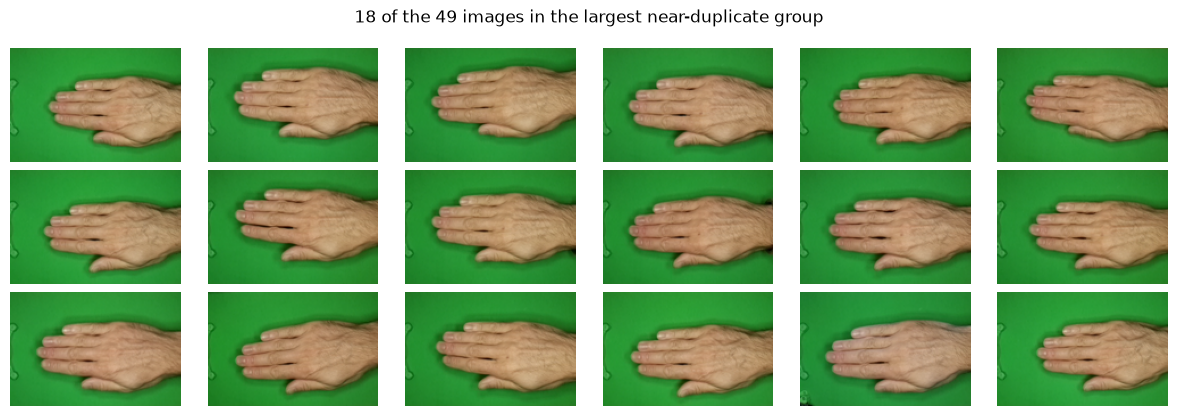

In [14]:
SOGLIA = 4
df['dup_group'] = trova_gruppi((dist <= SOGLIA) & stessa_classe)
df['dup_group_size'] = df['dup_group'].map(df['dup_group'].value_counts())

piu_grande = df['dup_group'].value_counts().index[0]
foto = df[df['dup_group'] == piu_grande]['path'].head(18)

plt.figure(figsize=(12, 4.2))
for i, path in enumerate(foto):
    plt.subplot(3, 6, i + 1)
    plt.imshow(Image.open(path).resize((150, 100)))
    plt.axis('off')
plt.suptitle('18 of the %d images in the largest near-duplicate group' % df['dup_group_size'].max())
plt.tight_layout()
plt.savefig(FIG_DIR + '/eda_largest_duplicate_group.png', dpi=150)
plt.show()

È una raffica di foto paper quasi identiche. Se le trattassi come foto indipendenti il risultato sul test
sarebbe gonfiato. Nello split ogni gruppo andrà tutto nello stesso set.

## Salvataggio
Salvo una tabella con una riga per immagine (etichetta, controlli, hash e gruppo) da usare nei prossimi notebook.

In [15]:
colonne = ['filename', 'label', 'width', 'height', 'mode', 'corrupted', 'md5', 'phash',
           'brightness', 'dup_group', 'dup_group_size']
df[colonne].to_csv(OUT_DIR + '/image_inventory.csv', index=False)
soglie.to_csv(OUT_DIR + '/eda_duplicate_thresholds.csv', index=False)
df[colonne].head()

,filename,label,width,height,mode,corrupted,md5,phash,brightness,dup_group,dup_group_size
0,04l5I8TqdzF9WDMJ.png,paper,300,200,RGB,False,52d7b81cffb337ffcd8e7c59baf675fa,977368cda55652a1,121.165094,0,1
1,0Og76sl5CJhbxWWx.png,paper,300,200,RGB,False,db076010f144fdb9a727a1792fb73099,91516aad541ad6eb,91.954428,1,2
2,0RA9rcrv8iVvuDDU.png,paper,300,200,RGB,False,123e05f495ddde7475f8e6dc8762f3b9,9199312f6d4d5656,124.697178,2,1
3,0Uomd0HvOB33m47I.png,paper,300,200,RGB,False,3d08d3fd484c9e9ced53c61984910d0d,964a69b1af56946a,93.250356,3,1
4,0a3UtNzl5Ll3sq8K.png,paper,300,200,RGB,False,1262ccba71452ac4fead832058848a97,93116c6ea5659e95,98.490133,4,1


## Riassunto
- l'archivio contiene una copia identica del dataset in `rps-cv-images`, che ignoro
- 2188 immagini: paper 712, rock 726, scissors 750 (quasi bilanciate, 2 di differenza dal README)
- tutte 300x200 RGB, nessun file corrotto, nessun duplicato esatto
- 405 immagini (19%) stanno in 130 gruppi di quasi-duplicati (pHash <= 4 bit, stessa classe)
- le classi si distinguono già dall'immagine media, lo sfondo e la luce sono sempre uguali

Prossimo passo: split train/validation/test stratificato per classe, tenendo ogni gruppo in un solo set.